# Observed FX errors and prediction intervals

All 582 matured decisions from the fixed 2026 snapshot are included: 194 per asset. Six unmatured decisions are excluded by publication dates. These are previously observed, current-vintage retrospective results; no model or interval policy is selected here. The frozen forecast export was independently checked against source-derived targets.

In [1]:
from pathlib import Path
import os, json, math, csv, hashlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks": ROOT = ROOT.parent
os.chdir(ROOT)
def read(path): return json.loads(Path(path).read_bytes())
report = read("docs/gated-observed-results.json")
assert report["rows"] == sum(report["counts"].values()) == 582
assert report["unmatured_excluded"]["rows"] == 6
assert report["weights_refitted"] is False and report["policy_reselected"] is False
FIGURES = ROOT / "docs/figures"
def show(fig, name):
    fig.tight_layout()
    path = FIGURES / (name + ".png")
    fig.savefig(path, dpi=150)
    plt.close(fig)
    display(Image(filename=str(path)))
display(pd.DataFrame.from_dict(report["decision_ranges"], orient="index"))

verification = report["current_artifact_verification"]
assert verification["score_carryover_authorized"] is True
assert verification["comparison_rows"] == 582 and verification["forecast_rows"] == 588
assert all(delta <= 1e-14 for delta in verification["max_abs_difference"].values())
assert all(delta == 0 for delta in verification["reload_max_abs_difference"].values())
print("Fresh calibrated artifact:", report["calibrated_bundle_sha256"])
print("Full-cohort forecast comparison:", verification["max_abs_difference"])
print("Independent audit:", verification["root_audit_sha256"])


,first_decision,last_decision,last_execution,last_target_maturity
FXEURCAD,2026-01-02,2026-10-09,2026-10-13,2026-10-14
FXGBPCAD,2026-01-02,2026-10-09,2026-10-13,2026-10-14
FXAUDCAD,2026-01-02,2026-10-09,2026-10-13,2026-10-14


Fresh calibrated artifact: ca28597f9ff5c6023ed6c945bc23cc5434cc47d3817c68c11826f02f04aca60e
Full-cohort forecast comparison: {'selected': 5.692061405548898e-18, 'selected_lower': 6.071532165918825e-18, 'selected_upper': 6.071532165918825e-18}
Independent audit: b9296e2ea0e2d3f3103ab44168010593a78e6e0740fbf0468280641b599ac847


## Point forecasts

The selected gate is compared with the same learned mean without gating, zero return, and the actual retained checkpoint. The retained checkpoint is a separate artifact, not an assumed alias of the new model. Its aggregate prediction error happens to match the ungated control in this cohort.

In [2]:
aggregate = report["metrics"]["aggregate"]
point = pd.DataFrame([
    {"model": "Selected gate", **aggregate["selected"]},
    {"model": "Ungated same mean", **aggregate["ungated_same_mean"]},
    {"model": "Zero return", **aggregate["zero"]},
    {"model": "Retained checkpoint", **report["true_legacy_comparator"]["regression"]},
])
display(point)
print("Selected relative RMSE change versus zero (%):", 100 * (aggregate["selected"]["rmse"] / aggregate["zero"]["rmse"] - 1))
print("Selected relative RMSE change versus retained (%):", 100 * (aggregate["selected"]["rmse"] / report["true_legacy_comparator"]["regression"]["rmse"] - 1))


,model,rows,rmse
0,Selected gate,582,0.002951
1,Ungated same mean,582,0.002957
2,Zero return,582,0.002952
3,Retained checkpoint,582,0.002957


Selected relative RMSE change versus zero (%): -0.021225561755477962
Selected relative RMSE change versus retained (%): -0.1866328695068198


,Selected gate,Ungated mean,Zero return
asset,,,
FXEURCAD,0.002409,0.002397,0.002400
FXGBPCAD,0.002672,0.002693,0.002683
FXAUDCAD,0.003631,0.003637,0.003630


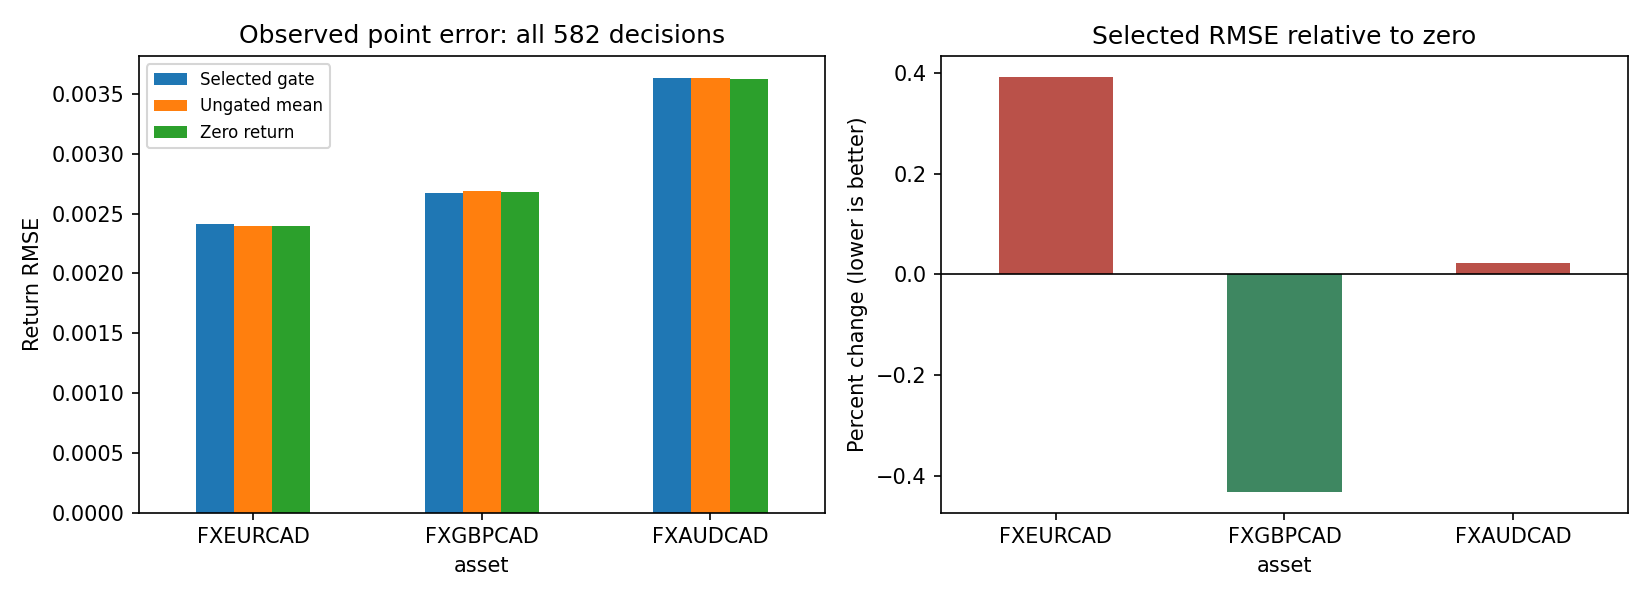

In [3]:
assets = []
for asset, metrics in report["metrics"]["per_asset"].items():
    assets.append({"asset": asset, "Selected gate": metrics["selected"]["rmse"], "Ungated mean": metrics["ungated_same_mean"]["rmse"], "Zero return": metrics["zero"]["rmse"]})
asset_errors = pd.DataFrame(assets).set_index("asset")
display(asset_errors)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
asset_errors.plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Observed point error: all 582 decisions", ylabel="Return RMSE")
axes[0].legend(fontsize=8)
delta = 100 * (asset_errors["Selected gate"] / asset_errors["Zero return"] - 1)
delta.plot.bar(ax=axes[1], color=["#ba5149" if x > 0 else "#3e8761" for x in delta], rot=0)
axes[1].axhline(0, color="black", linewidth=.8)
axes[1].set(title="Selected RMSE relative to zero", ylabel="Percent change (lower is better)")
show(fig, "selected_gate_observed_point_errors")


The aggregate difference from zero is tiny. The selected forecast improves GBP/CAD but is slightly worse than zero for EUR/CAD and AUD/CAD. This comparison does not establish trading profit, stability across future periods, or independent confirmation.

## Fixed 90% intervals

Intervals use the separately calibrated 2025 residual quantiles. Proper interval score penalizes both excessive width and missed observations. Empirical coverage below 90% does not meet the nominal level; serial dependence and nonstationarity prevent a general coverage guarantee.

,model,rows,nominal_coverage,coverage,mean_width,mean_interval_score
0,Selected gate,582,0.9,0.883162,0.009490,0.013099
1,Retained checkpoint,582,0.9,0.881443,0.009413,0.013144


,rows,nominal_coverage,coverage,mean_width,mean_interval_score
asset,,,,,
FXEURCAD,194,0.9,0.876289,0.007475,0.010626
FXGBPCAD,194,0.9,0.907216,0.009754,0.012062
FXAUDCAD,194,0.9,0.865979,0.011241,0.016608


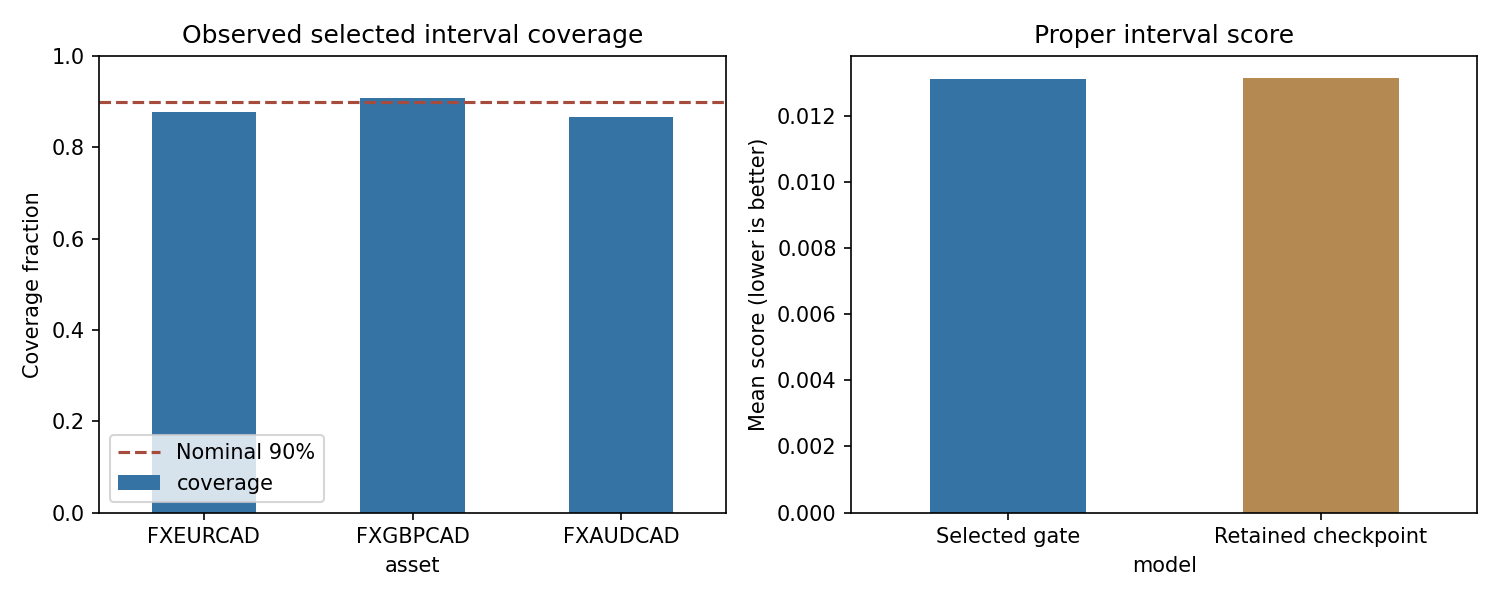

In [4]:
interval_table = pd.DataFrame([
    {"model": "Selected gate", **aggregate["selected_intervals"]},
    {"model": "Retained checkpoint", **report["true_legacy_comparator"]["intervals"]},
])
display(interval_table)
interval_assets = pd.DataFrame([
    {"asset": asset, **metrics["selected_intervals"]}
    for asset, metrics in report["metrics"]["per_asset"].items()
]).set_index("asset")
display(interval_assets)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
interval_assets.coverage.plot.bar(ax=axes[0], rot=0, color="#3573a5")
axes[0].axhline(.9, color="#a54c3d", linestyle="--", label="Nominal 90%")
axes[0].set(ylim=(0, 1), title="Observed selected interval coverage", ylabel="Coverage fraction")
axes[0].legend()
interval_table.set_index("model").mean_interval_score.plot.bar(ax=axes[1], rot=0, color=["#3573a5", "#b48a52"])
axes[1].set(title="Proper interval score", ylabel="Mean score (lower is better)")
show(fig, "selected_gate_observed_intervals")


## Independent numerical replay

The optional replay below reads the private frozen CSV only. It computes no new predictions, fits no weights, and changes no policy. The saved execution and export receipts bind the complete ordered cohort and original model artifacts.

In [5]:
def rmse(rows, key):
    return math.sqrt(math.fsum((float(x["target"]) - float(x[key])) ** 2 for x in rows) / len(rows))

def interval_metrics(rows, prefix):
    widths = [float(x[prefix + "_upper"]) - float(x[prefix + "_lower"]) for x in rows]
    assert min(widths) >= 0
    covered = sum(float(x[prefix + "_lower"]) <= float(x["target"]) <= float(x[prefix + "_upper"]) for x in rows)
    score = math.fsum(width + 20 * max(float(x[prefix + "_lower"]) - float(x["target"]), 0) + 20 * max(float(x["target"]) - float(x[prefix + "_upper"]), 0) for x, width in zip(rows, widths)) / len(rows)
    return {"coverage": covered / len(rows), "mean_width": math.fsum(widths) / len(rows), "mean_interval_score": score}

path = ROOT / "data/interim/gated-evaluation-export-v1-reviewed/output-v1/forecast-export/predictions.csv"
if path.exists():
    assert hashlib.sha256(path.read_bytes()).hexdigest() == report["prediction_export_sha256"]
    with path.open(encoding="utf8", newline="") as stream: rows = list(csv.DictReader(stream))
    ids = [(x["asset"], x["date"], x["execution_date"], x["target_date"]) for x in rows]
    assert len(rows) == len(set(ids)) == 582
    assert hashlib.sha256(json.dumps(ids, sort_keys=True, separators=(",", ":")).encode()).hexdigest() == report["decision_ids_sha256"]
    for asset in [None] + list(report["counts"]):
        selected_rows = [x for x in rows if asset is None or x["asset"] == asset]
        expected = aggregate if asset is None else report["metrics"]["per_asset"][asset]
        for key in ["selected", "ungated_same_mean", "zero"]:
            assert abs(rmse(selected_rows, key) - expected[key]["rmse"]) < 1e-14
        for key, value in interval_metrics(selected_rows, "selected").items():
            assert abs(value - expected["selected_intervals"][key]) < 1e-14
        legacy = report["true_legacy_comparator"] if asset is None else report["true_legacy_comparator"]["per_asset"][asset]
        assert abs(rmse(selected_rows, "true_legacy") - legacy["regression"]["rmse"]) < 1e-14
        for key, value in interval_metrics(selected_rows, "true_legacy").items():
            assert abs(value - legacy["intervals"][key]) < 1e-14
    print("Verified all 582 rows: aggregate and per-asset errors and proper interval metrics.")
else:
    print("Private frozen CSV required for numerical replay; no new metrics computed.")


Verified all 582 rows: aggregate and per-asset errors and proper interval metrics.


Reference rates omit transaction costs, bid/ask execution, funding and market impact. Holiday gaps follow the publication calendar. Current-vintage observations cannot reconstruct what was available at every historical decision. Keep raw rates, predictions, checkpoints and credentials in ignored local storage.